# Лабораторная работа № 3 «Интеграционное и API-тестирование»

## Цель

Освоить тестирование REST API на примере открытого публичного сервиса: научиться строить в Postman коллекцию запросов, писать автоматические проверки и анализировать расхождения между документацией и фактическим поведением API.

## Тестируемая система

**Restful-Booker**, открытое учебное API бронирования отелей: https://restful-booker.herokuapp.com (документация: https://restful-booker.herokuapp.com/apidoc/index.html). Docker и локальный запуск не нужны, достаточно Postman и доступа в интернет.

| Метод | Эндпоинт | Назначение |
|---|---|---|
| POST | `/auth` | получение токена (логин `admin`, пароль `password123`) |
| GET | `/booking` | список идентификаторов бронирований (с фильтрами) |
| GET | `/booking/{id}` | получение бронирования |
| POST | `/booking` | создание бронирования |
| PUT | `/booking/{id}` | полное обновление (нужна авторизация) |
| PATCH | `/booking/{id}` | частичное обновление (нужна авторизация) |
| DELETE | `/booking/{id}` | удаление (нужна авторизация) |
| GET | `/ping` | проверка работоспособности |

## Задание

1. Создайте в Postman коллекцию `LabAPI_<Фамилия>` с переменными окружения (`baseUrl`, `token`, `bookingId`) и папками по ресурсам: `Auth`, `Booking`, `Health`.

2. Добавьте запросы **ко всем эндпоинтам** из таблицы. Для каждого запроса напишите описание: цель, входные данные, ожидаемый результат.

3. Автоматизируйте получение токена. В запросе `POST /auth` скриптом во вкладке Tests сохраните токен в переменную окружения. В запросе создания бронирования сохраните `bookingid`.

4. Составьте и выполните тест-кейсы в каждой категории:

   - **Позитивные**: создание → получение → обновление (PUT и PATCH) → удаление → повторное получение (ожидается 404).
   - **Негативные**: неверный логин или пароль, запрос без токена и с некорректным токеном, несуществующий `id`, некорректный JSON, неверный тип данных (например, строка в `totalprice`), отсутствие обязательных полей.
   - **Граничные значения**: пустые строки, очень длинные строки (1000+ символов), `totalprice` = 0, отрицательное и очень большое число, дата `checkout` раньше `checkin`, невалидный формат даты.
   - **Коды ответов**: для каждого теста явно укажите ожидаемый код (200, 201, 400, 403/401, 404, 405, 500). По возможности вызовите разные коды.

5. Для каждого запроса добавьте во вкладку Tests минимум 3 автоматические проверки, например:

   ```javascript
   pm.test("Статус 200", () => pm.response.to.have.status(200));
   pm.test("Время ответа < 2000 мс", () => pm.expect(pm.response.responseTime).to.be.below(2000));
   pm.test("Есть поле bookingid", () => pm.expect(pm.response.json()).to.have.property("bookingid"));
   ```

6. Запустите всю коллекцию через **Collection Runner** и убедитесь, что цепочка сценариев работает без ручного вмешательства (токен и `id` передаются через переменные).

7. **Фактическое и ожидаемое поведение.** Это публичное учебное API, и его реальное поведение может отличаться от документации и от «правильного» REST (нестандартные коды для ошибок, код ответа для DELETE и т. д.). Оформите таблицу расхождений:

   | № | Запрос | Ожидалось (по REST/документации) | Получено | Вывод (дефект / особенность) |
   |---|---|---|---|---|

## Отчет о выполнении

### 1. Название сервиса и краткое описание тестируемых эндпоинтов

В ходе работы тестировалось публичное API **Restful-Booker**.
Была создана коллекция LabAPI_Babukhina с папками Auth, Booking, Health и настроено окружение с переменными baseUrl, token, bookingId.
Автоматизация процесса реализована через скрипты во вкладке Scripts:
* В POST /auth токен автоматически извлекается из ответа и сохраняется в переменную окружения {{token}}.
* В POST /booking созданный идентификатор сохраняется в переменную {{bookingId}}, что позволяет выполнять цепочку запросов (GET, PUT, PATCH, DELETE) без ручного вмешательства.

   ```javascript
    pm.test("Статус 200", () => pm.response.to.have.status(200));
    pm.test("Время ответа < 2000 мс", () => pm.expect(pm.response.responseTime).to.be.below(2000));

    const json = pm.response.json();
    if (json.token) {
      pm.environment.set("token", json.token);
      console.log("Токен сохранён:", json.token);
    } else {
      pm.test("Токен присутствует в ответе", () => {
        pm.expect.fail("Поле token отсутствует");
    });
   ```


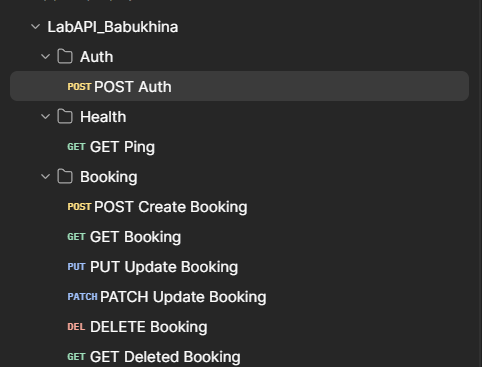

### 2. Таблица тест-кейсов

| ID | Название запроса | Эндпоинт | Тип | Входные данные / Условия | Ожидаемый результат | Фактический результат | Статус |
|---|---|---|---|---|---|---|---|
| TC-01 | POST Auth | POST /auth | Позитивный | Валидные логин и пароль | 200 OK | 200 OK | Pass |
| TC-02 | POST Create Booking | POST /booking | Позитивный | Валидный JSON | 200 OK | 200 OK | Pass |
| TC-03 | GET Booking | GET /booking/{id} | Позитивный | ID из переменной | 200 OK | 200 OK | Pass |
| TC-04 | PUT Update Booking | PUT /booking/{id} | Позитивный | Валидный JSON + Cookie | 200 OK | 200 OK | Pass |
| TC-05 | PATCH Update Booking | PATCH /booking/{id} | Позитивный | {"totalprice": 250} + Cookie | 200 OK | 200 OK | Pass |
| TC-06 | DELETE Booking | DELETE /booking/{id} | Позитивный | Cookie (токен) | 204 или 200 | 201 Created | Pass (особенность) |
| TC-07 | GET Deleted Booking | GET /booking/{id} | Позитивный | ID удаленной брони | 404 Not Found | 404 Not Found | Pass |
| TC-08 | GET Ping | GET /ping | Позитивный | Без тела | 200 OK | 201 Created | Fail (особенность) |
| TC-09 | Auth Bad Password | POST /auth | Негативный | Неверный пароль | 401 Unauthorized | 200 OK | Fail (дефект) |
| TC-10 | PUT No Token | PUT /booking/{id} | Негативный | Без заголовка Cookie | 403 Forbidden | 403 Forbidden | Pass |
| TC-11 | PUT Bad Token | PUT /booking/{id} | Негативный | Cookie: token=invalid_123 | 403 Forbidden | 403 Forbidden | Pass |
| TC-12 | GET Invalid ID | GET /booking/999999 | Негативный | Несуществующий id | 404 Not Found | 404 Not Found | Pass |
| TC-13 | POST Bad JSON | POST /booking | Негативный | Некорректный JSON | 400 Bad Request | 400 Bad Request | Pass (обработано) |
| TC-14 | POST Wrong Type | POST /booking | Негативный | "totalprice": "сто" | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-15 | POST Missing Field | POST /booking | Негативный | Отсутствует firstname | 400 Bad Request | 500 Internal Server Error | Fail (дефект) |
| TC-16 | Bound Empty String | POST /booking | Граничный | "firstname": "" | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-17 | Bound Long String | POST /booking | Граничный | firstname 1000+ символов | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-18 | Bound Price 0 | POST /booking | Граничный | "totalprice": 0 | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-19 | Bound Price Negative | POST /booking | Граничный | "totalprice": -100 | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-20 | Bound Price Huge | POST /booking | Граничный | "totalprice": 999999999 | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-21 | Bound Date Logic | POST /booking | Граничный | checkout раньше checkin | 400 Bad Request | 200 OK | Fail (дефект) |
| TC-22 | Bound Date Format | POST /booking | Граничный | Невалидная дата (2026-13-45) | 400 Bad Request | 200 OK | Fail (дефект) |

### 3. Таблица расхождений с документацией и список найденных дефектов

### Таблица расхождений
| № | Запрос | Ожидалось (по REST/документации) | Получено | Вывод (дефект / особенность) |
|---|---|---|---|---|
| 1 | GET /ping | 200 OK | 201 Created | Особенность API (нестандартный код для проверки живости). |
| 2 | DELETE /booking/{id} | 204 No Content или 200 OK | 201 Created | Особенность API (удаление возвращает код создания). |
| 3 | POST /auth (неверный пароль) | 401 Unauthorized | 200 OK с телом {"reason": "Bad credentials"} | Дефект: ошибка аутентификации не отражается HTTP-кодом. |
| 4 | POST /booking (невалидный JSON) | 400 Bad Request | 400 Bad Request | Обработано корректно (сервер вернул 400). |
| 5 | POST /booking (отсутствует поле) | 400 Bad Request | 500 Internal Server Error | Дефект: сервер падает при отсутствии обязательных полей. |

### Список найденных дефектов

Баг №1: Неверный статус-код при ошибке авторизации
*   Шаги: Отправить POST /auth (Auth Bad Password) с неверным паролем.
*   Ожидаемый результат: Код 401 Unauthorized.
*   Фактический результат: Код 200 OK, в теле {"reason": "Bad credentials"}.
*   Серьёзность: Major.

Баг №2: Отсутствие валидации типов данных (падение сервера)
*   Шаги: Отправить POST /booking (POST Missing Field) без поля firstname или с неверным типом (POST Wrong Type).
*   Ожидаемый результат: Код 400 Bad Request с описанием ошибки.
*   Фактический результат: В случае отсутствия поля — 500 Internal Server Error. В случае неверного типа — 200 OK (бронь создана).
*   Серьёзность: Critical.

Баг №3: Отсутствие логической валидации и проверки граничных значений
*   Шаги: Отправить POST /booking с пустой строкой (Bound Empty String), отрицательной ценой (Bound Price Negative) или датой выезда раньше даты заезда (Bound Date Logic).
*   Ожидаемый результат: Код 400 Bad Request (отклонение некорректных данных).
*   Фактический результат: Код 200 OK. Бронь успешно создается, API возвращает bookingid.
*   Серьёзность: Major. Отсутствие валидации бизнес-логики может привести к созданию броней с отрицательной стоимостью или невозможными датами.

### 4. Скриншоты прогона коллекции в Collection Runner


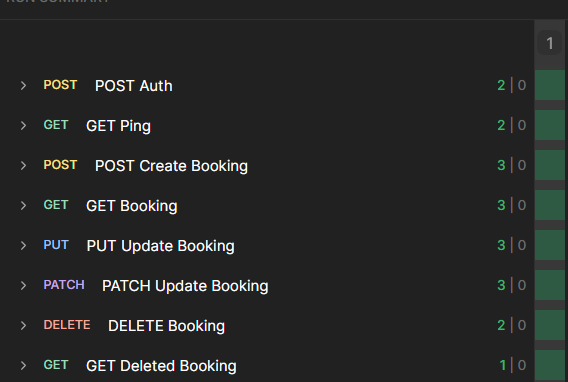

### 5. Негативные и граничные тесты


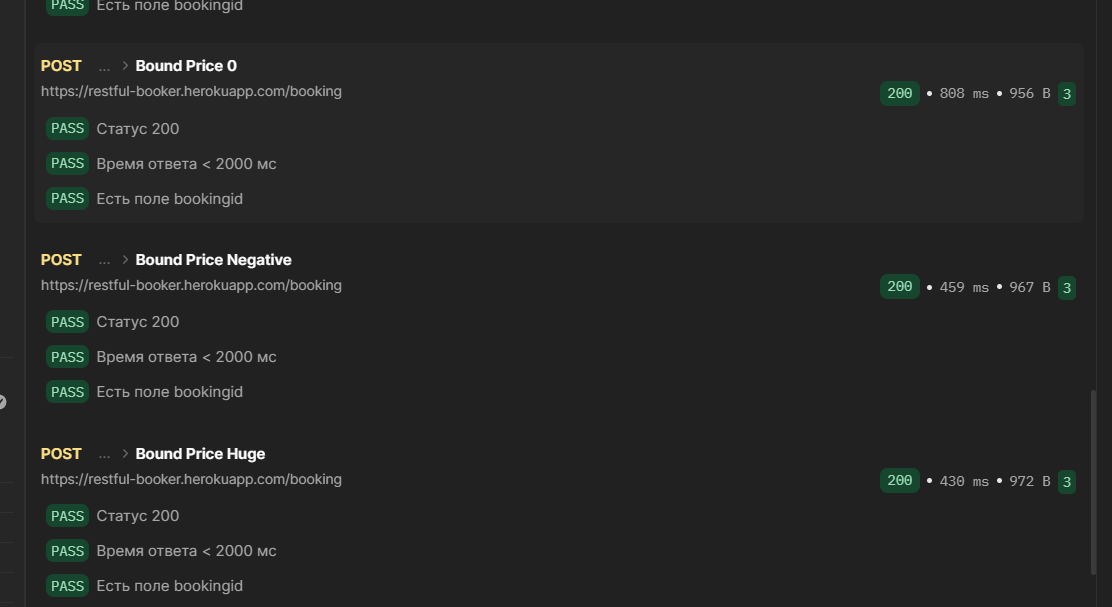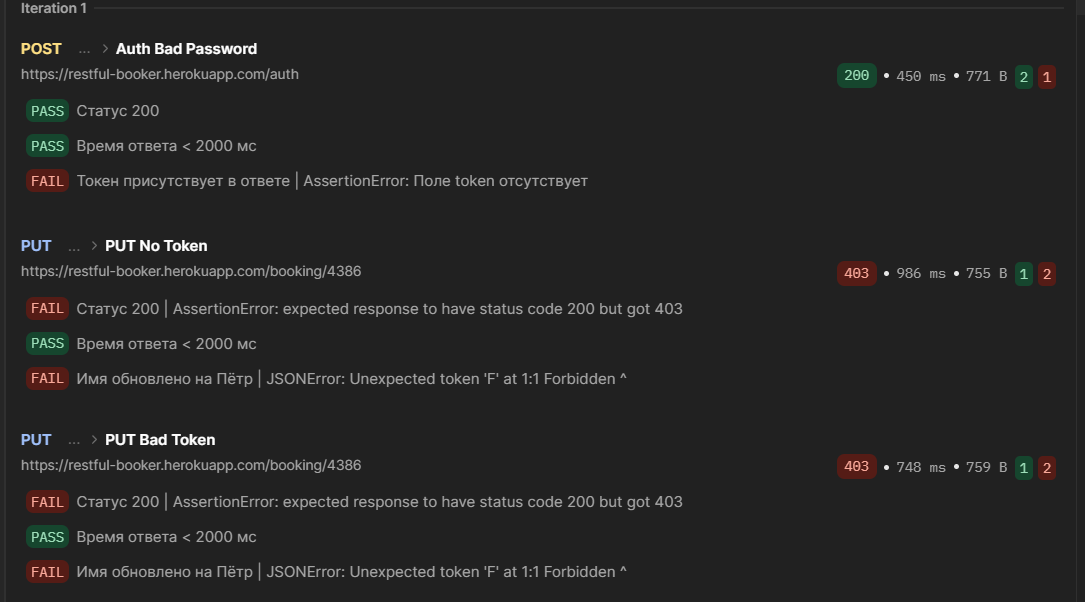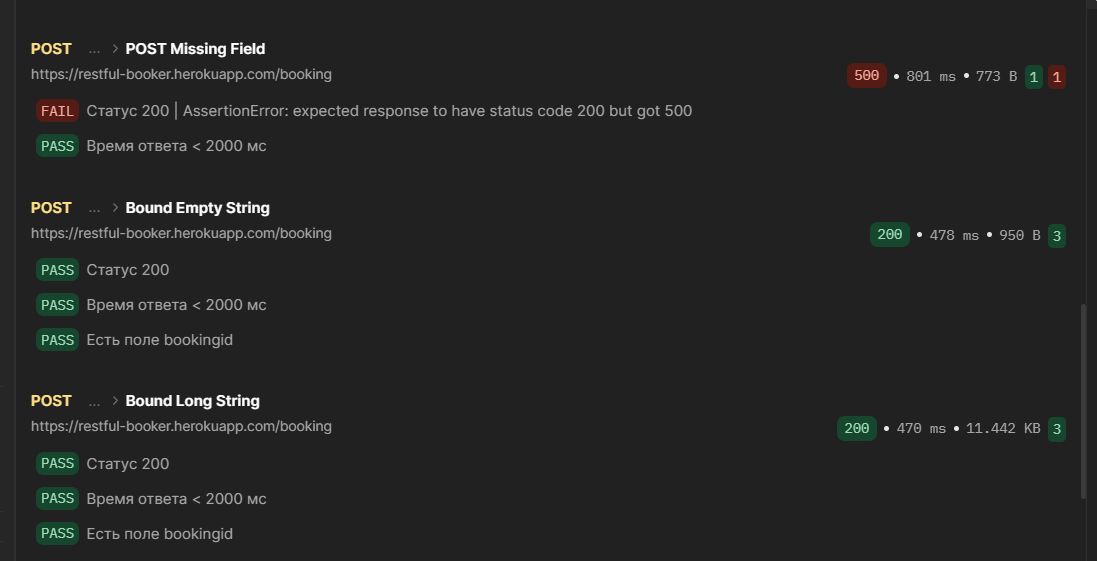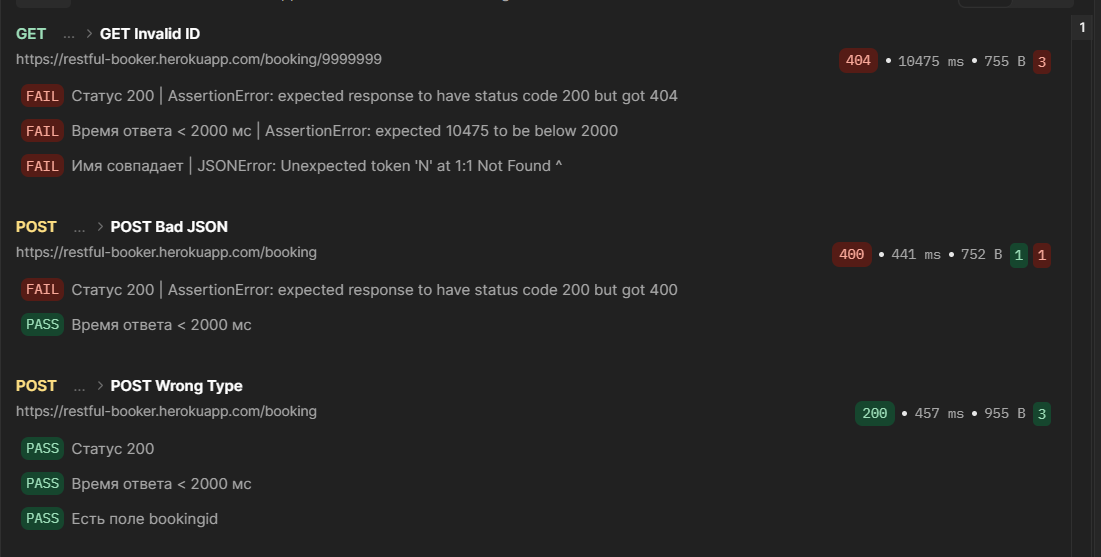

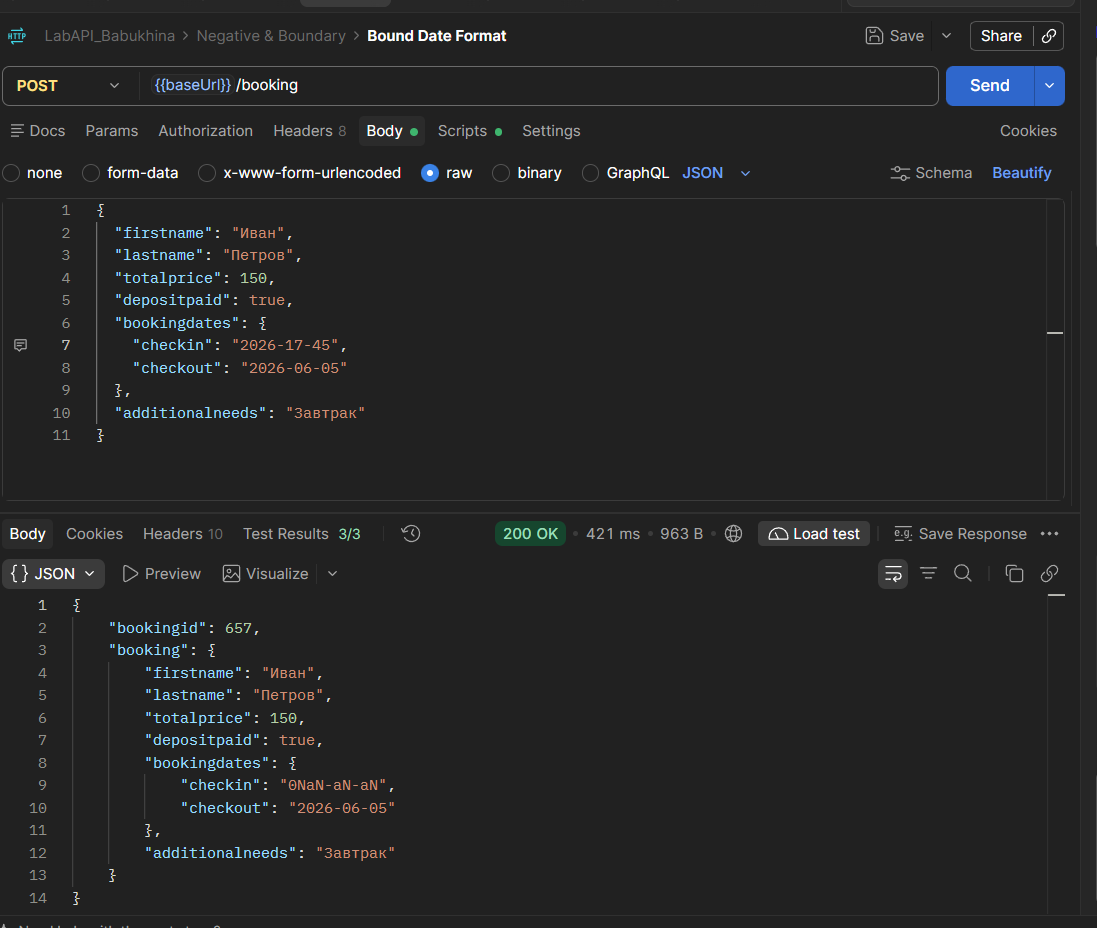

### Выводы

В ходе выполнения лабораторной работы было освоено тестирование REST API с использованием Postman. Была создана коллекция запросов, покрывающая все эндпоинты Restful-Booker, настроены переменные окружения для автоматической передачи token и bookingId, что позволило провести сквозное тестирование без ручного вмешательства.

В результате тестирования было выявлено, что API имеет ряд существенных дефектов валидации: оно принимает пустые строки, отрицательные цены и некорректные даты, создавая при этом успешные бронирования. Кроме того, обнаружено расхождение документации и реального поведения API (использование Cookie вместо Bearer Token, а также возврат кода 200 при ошибке авторизации). Это доказывает, что при тестировании API необходимо опираться на фактическое поведение системы, а не только на документацию.